# RQ1 - How do English texts decay under repeated English→Spanish→English round trips?

**Question.** When a text goes through round trips T0 → S1 → T1 → S2 → T2 → S3 → T3, how much of its wording (lexical),
meaning (semantic), style and information survives, and do translators differ in that decay?

**Design.**
- **Inputs:** the same 200 XSum T0 documents (31 original articles × 7 source labels: Human + 6 LLM generators).
- **Chains:** every translator runs every document independently through three round trips. No translator ever reads
  another's output.
- **Comparisons:** each English stage is compared with the original (**T0 → Tk**, cumulative) and with the previous
  English stage (**Tk-1 → Tk**, consecutive).
- **Primary cohort:** the *matched* cohort, i.e. documents whose chain is complete (all six stages valid) for **every**
  translator. All translators are then compared on exactly the same documents. The full available cohort is
  reported as a supplement.
- **Uncertainty:** 95% confidence intervals come from an article-cluster bootstrap. The statistical unit is the
  **original article**, because the seven texts of one article share content.

**Where the numbers come from.** Every metric was computed once by a shared, cached pipeline, then aggregated here. Definitions are summarised in [`../README.md`](../README.md). Translators are discovered from the finalized datasets, so a newly added translator appears here automatically.

> **Public copy** by Samer Ahmed. This notebook was executed end to end from a clean kernel on 2026-11-01, and its saved outputs (tables, figures, interpretation) are shown as they were produced. The code cells call a shared research package and local, unpublished text tables (XSum texts and their translations) that are not part of this folder. They live in the development workspace (`Sam/` on branch `feature/sam-experiments`), so re-running needs that workspace. The aggregate result tables are in [`../results/`](../results/) and the figures in [`../figures/`](../figures/).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "sot_research").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sot_research import analysis, classify, corpus, features, paths, plots

%matplotlib inline
plots.setup()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 3)
CFG = corpus.research_config()
SEED, NB, NR = CFG["seed"], CFG["bootstrap_samples"], CFG["cv_repeats"]
print("python", sys.version.split()[0], "|", Path(sys.executable).parent.parent.name, "| pandas", pd.__version__)

D = analysis.load(require_text=True)
P, TR, NAMES, COL, T = D["pairs"], D["translators"], D["names"], D["colors"], D["texts"]
OUT = paths.results("rq1")
TR_PAIRS = P[P.translator.isin(TR)]
MATCHED = TR_PAIRS[TR_PAIRS.matched]
BASE = P[P.translator == "baseline"]
print("translators (discovered):", [NAMES[t] for t in TR])
print("matched cohort:", len(D["matched_items"]), "documents from",
      D["cohort"][D["cohort"].matched].article_id.nunique(), "articles")

python 3.12.15 | .venv-research | pandas 2.2.3


translators (discovered): ['MADLAD-400-3B', 'NLLB-200-1.3B', 'Qwen3-4B']
matched cohort: 193 documents from 31 articles


## 1. Data coverage and attrition

In [2]:
chains = D["chains"]
cov = (chains.groupby("translator").agg(documents=("item_id", "nunique"), complete_chains=("complete", "sum"))
       .reindex(TR))
cov["incomplete"] = cov.documents - cov.complete_chains
cov["matched_cohort"] = len(D["matched_items"])
cov.index = [NAMES[t] for t in cov.index]
display(cov)

stage_cov = pd.read_csv(paths.results("data_coverage") / "coverage_by_stage.csv")
stage_cov["translator"] = stage_cov.translator.map(NAMES)
display(stage_cov.set_index(["translator", "stage"]).unstack("stage")["valid"][corpus.STAGES])

inv = T[T.status == "invalid"][["translator", "stage", "item_id", "source_label", "validation_reason"]]
inv = inv.assign(translator=inv.translator.map(NAMES)).sort_values(["translator", "stage"])
print(f"{len(inv)} invalid records (kept as attrition, never repaired); every later stage of those chains is blocked:")
display(inv.reset_index(drop=True))

,documents,complete_chains,incomplete,matched_cohort
MADLAD-400-3B,200,196,4,193
NLLB-200-1.3B,200,197,3,193
Qwen3-4B,200,200,0,193


stage,S1,T1,S2,T2,S3,T3
translator,,,,,,
MADLAD-400-3B,197,197,197,196,196,196
NLLB-200-1.3B,200,199,199,198,198,197
Qwen3-4B,200,200,200,200,200,200


10 invalid records (kept as attrition, never repaired); every later stage of those chains is blocked:


,translator,stage,item_id,source_label,validation_reason
0,MADLAD-400-3B,S1,xsum|BigScience|xsum-4713,BigScience,legacy:generation_cap;legacy:direction_unattri...
1,MADLAD-400-3B,S1,xsum|LLAMA|xsum-4714,LLAMA,legacy:generation_cap;legacy:severe_expansion;...
2,MADLAD-400-3B,S1,xsum|LLAMA|xsum-4733,LLAMA,legacy:generation_cap;legacy:direction_unattri...
3,MADLAD-400-3B,T1,xsum|BigScience|xsum-4713,BigScience,legacy:generation_cap;legacy:direction_unattri...
4,MADLAD-400-3B,T1,xsum|LLAMA|xsum-4714,LLAMA,legacy:generation_cap;legacy:severe_expansion;...
5,MADLAD-400-3B,T1,xsum|LLAMA|xsum-4733,LLAMA,legacy:generation_cap;legacy:direction_unattri...
6,MADLAD-400-3B,T2,xsum|Eleuther-AI|xsum-4729,Eleuther-AI,engine:generation_cap
7,NLLB-200-1.3B,T1,xsum|Eleuther-AI|xsum-4737,Eleuther-AI,check:repetition
8,NLLB-200-1.3B,T2,xsum|Eleuther-AI|xsum-4725,Eleuther-AI,check:repetition
9,NLLB-200-1.3B,T3,xsum|Tsinghua|xsum-4722,Tsinghua,check:repetition


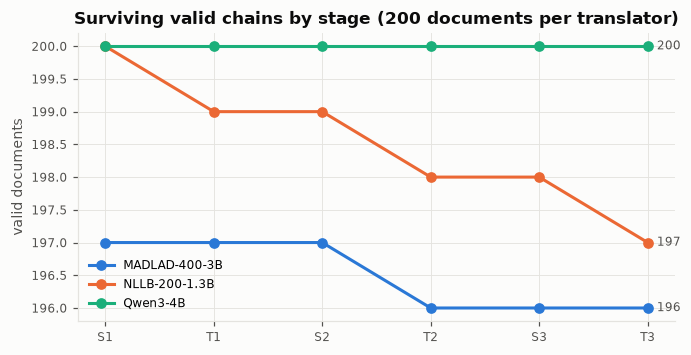

translator,MADLAD-400-3B,NLLB-200-1.3B,Qwen3-4B
incomplete chains by source,,,
BigScience,1,0,0
Eleuther-AI,1,2,0
Human,0,0,0
LLAMA,2,0,0
OpenAI,0,0,0
PaLM,0,0,0
Tsinghua,0,1,0


In [3]:
fig, ax = plt.subplots(figsize=(7, 3.4))
sc = pd.read_csv(paths.results("data_coverage") / "coverage_by_stage.csv")
for t in TR:
    s = sc[sc.translator == t].set_index("stage").reindex(corpus.STAGES)
    ax.plot(range(6), s["valid"], marker="o", color=COL[t], label=NAMES[t])
    ax.annotate(f"{int(s['valid'].iloc[-1])}", (5, s["valid"].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=plots.INK2)
ax.set_xticks(range(6), corpus.STAGES)
ax.set_ylabel("valid documents")
ax.set_title("Surviving valid chains by stage (200 documents per translator)")
ax.legend(loc="lower left")
plots.save(fig, "rq1_attrition_by_stage")
plt.show()
by_src = chains.groupby(["source_label", "translator"]).complete.agg(["sum", "size"])
display((by_src["size"] - by_src["sum"]).unstack("translator").rename(columns=NAMES).rename_axis(
    index="incomplete chains by source"))

**Missingness.** Attrition is small, at most 4 of 200 documents per translator, and it is reported, not imputed.
- **Cause:** every invalid record failed a blocking check: degenerate repetition, or a generation that hit its token
  cap.
- **Consequence:** the later stages of those chains were never generated, by design, because an invalid output is
  never fed into another round.
- **Missing data:** missing chains are *not* missing at random. Repetition loops occur in particular documents. This
  is why translator comparisons use the matched cohort.

## 2. Summary statistics (T0 → Tk, matched cohort)

In [4]:
CUM_METRICS = [m for m in analysis.METRICS if m in P.columns]
cum = TR_PAIRS[TR_PAIRS.kind == "cumulative"]
summ = pd.concat([analysis.cluster_ci(cum[cum.matched], ["translator", "hyp_stage"], m, n_boot=NB, seed=SEED)
                  .assign(cohort="matched") for m in CUM_METRICS] +
                 [analysis.cluster_ci(cum, ["translator", "hyp_stage"], m, n_boot=NB, seed=SEED)
                  .assign(cohort="all_available") for m in CUM_METRICS], ignore_index=True)
summ.to_csv(OUT / "summary_cumulative.csv", index=False)
base = pd.concat([analysis.cluster_ci(BASE, ["kind"], m, n_boot=NB, seed=SEED) for m in CUM_METRICS])
base.to_csv(OUT / "baselines.csv", index=False)

show = ["bleu", "chrf", "word_retention", "e5_cosine", "mpnet_cosine", "bertscore_f1", "burrows_delta",
        "entity_recall", "number_recall", "sent_coverage"]
tab = summ[(summ.cohort == "matched") & summ.metric.isin(show)].copy()
tab["value"] = tab.apply(analysis.fmt_ci, axis=1)
tab["translator"] = tab.translator.map(NAMES)
wide = tab.pivot_table(index=["metric"], columns=["translator", "hyp_stage"], values="value", aggfunc="first")
display(wide.reindex(show))
print("n pairs per cell (matched):", tab.groupby(["translator", "hyp_stage"]).n_pairs.max().to_dict())
bt = base[base.metric.isin(show)].pivot_table(index="metric", columns="kind", values="mean").reindex(show)
display(bt.rename(columns={"unrelated": "unrelated T0 pair (floor)",
                           "cross_source": "same article, other author (Human vs LLM T0)"}))

translator             MADLAD-400-3B                                                     NLLB-200-1.3B                                                          Qwen3-4B                        \
hyp_stage                         T1                    T2                    T3                    T1                    T2                    T3                    T1                    T2   
metric                                                                                                                                                                                           
bleu            0.591 [0.569, 0.613]  0.555 [0.529, 0.581]  0.547 [0.521, 0.574]  0.639 [0.621, 0.660]  0.624 [0.604, 0.646]  0.615 [0.594, 0.640]  0.450 [0.427, 0.469]  0.429 [0.406, 0.450]   
chrf            0.777 [0.758, 0.795]  0.749 [0.727, 0.771]  0.743 [0.720, 0.765]  0.811 [0.798, 0.824]  0.801 [0.788, 0.816]  0.798 [0.785, 0.813]  0.708 [0.695, 0.720]  0.693 [0.679, 0.707]   
word_retention  0.815 [0.796, 0.834]  0.786 [0.763, 0.808]  0.779 [0.755, 0.803]  0.849 [0.840, 0.860]  0.840 [0.830, 0.852]  0.839 [0.828, 0.850]  0.753 [0.739, 0.768]  0.737 [0.721, 0.753]   
e5_cosine       0.979 [0.975, 0.982]  0.974 [0.969, 0.978]  0.973 [0.968, 0.978]  0.987 [0.984, 0.989]  0.986 [0.983, 0.988]  0.985 [0.983, 0.988]  0.980 [0.978, 0.982]  0.978 [0.976, 0.981]   
mpnet_cosine    0.951 [0.939, 0.961]  0.941 [0.928, 0.952]  0.939 [0.925, 0.951]  0.977 [0.973, 0.980]  0.971 [0.965, 0.977]  0.969 [0.962, 0.976]  0.966 [0.961, 0.970]  0.964 [0.959, 0.968]   
bertscore_f1    0.966 [0.962, 0.969]  0.961 [0.957, 0.965]  0.960 [0.956, 0.965]  0.973 [0.970, 0.976]  0.970 [0.967, 0.974]  0.968 [0.963, 0.972]  0.959 [0.956, 0.962]  0.956 [0.953, 0.959]   
burrows_delta   0.172 [0.154, 0.191]  0.193 [0.174, 0.214]  0.199 [0.178, 0.220]  0.148 [0.135, 0.160]  0.160 [0.146, 0.173]  0.174 [0.155, 0.191]  0.239 [0.222, 0.258]  0.254 [0.236, 0.274]   
entity_recall   0.860 [0.815, 0.897]  0.831 [0.783, 0.876]  0.827 [0.779, 0.871]  0.943 [0.922, 0.961]  0.934 [0.911, 0.954]  0.933 [0.911, 0.954]  0.891 [0.863, 0.919]  0.883 [0.853, 0.910]   
number_recall   0.875 [0.817, 0.925]  0.833 [0.765, 0.894]  0.826 [0.763, 0.886]  0.937 [0.886, 0.973]  0.932 [0.881, 0.969]  0.932 [0.883, 0.970]  0.905 [0.835, 0.962]  0.900 [0.829, 0.960]   
sent_coverage   0.920 [0.900, 0.939]  0.883 [0.855, 0.910]  0.875 [0.843, 0.907]  0.975 [0.967, 0.983]  0.974 [0.966, 0.981]  0.976 [0.969, 0.983]  0.981 [0.974, 0.988]  0.974 [0.963, 0.983]   

translator                            
hyp_stage                         T3  
metric                                
bleu            0.422 [0.401, 0.444]  
chrf            0.688 [0.675, 0.702]  
word_retention  0.732 [0.717, 0.748]  
e5_cosine       0.978 [0.976, 0.980]  
mpnet_cosine    0.962 [0.958, 0.967]  
bertscore_f1    0.955 [0.952, 0.958]  
burrows_delta   0.258 [0.239, 0.277]  
entity_recall   0.881 [0.854, 0.907]  
number_recall   0.899 [0.832, 0.955]  
sent_coverage   0.974 [0.964, 0.983]

n pairs per cell (matched): {('MADLAD-400-3B', 'T1'): 193, ('MADLAD-400-3B', 'T2'): 193, ('MADLAD-400-3B', 'T3'): 193, ('NLLB-200-1.3B', 'T1'): 193, ('NLLB-200-1.3B', 'T2'): 193, ('NLLB-200-1.3B', 'T3'): 193, ('Qwen3-4B', 'T1'): 193, ('Qwen3-4B', 'T2'): 193, ('Qwen3-4B', 'T3'): 193}


kind,"same article, other author (Human vs LLM T0)",unrelated T0 pair (floor)
metric,,
bleu,0.113,0.007
chrf,0.331,0.223
word_retention,0.323,0.227
e5_cosine,0.903,0.724
mpnet_cosine,0.753,0.125
bertscore_f1,0.859,0.801
burrows_delta,0.567,0.762
entity_recall,0.301,0.018
number_recall,0.228,0.033


In [5]:
F = D["features"]
L = F[F.item_id.isin(D["matched_items"])]
lens = (L.groupby(["translator", "stage"]).agg(words=("n_words", "mean"), sentences=("n_sentences", "mean"),
                                               sentence_len=("sent_len_mean", "mean"), mattr=("mattr", "mean"))
        .reset_index())
lens["translator"] = lens.translator.map(lambda t: NAMES.get(t, "original T0"))
display(lens.set_index(["translator", "stage"]).round(2))

words  sentences  sentence_len  mattr
translator    stage                                        
MADLAD-400-3B T1     228.81      10.94         23.35   0.82
              T2     222.16      10.44         24.52   0.82
              T3     220.11      10.28         25.00   0.82
NLLB-200-1.3B T1     236.57      11.98         21.14   0.83
              T2     237.02      12.55         20.49   0.83
              T3     241.17      14.11         19.94   0.82
original T0   T0     242.49      11.85         21.82   0.84
Qwen3-4B      T1     233.55      11.74         21.23   0.83
              T2     232.38      11.70         21.18   0.83
              T3     232.09      11.69         21.13   0.83

## 3. Decay relative to the original (T0 → T1, T2, T3)

Each panel shows one metric. Lines are translator means with 95% article-cluster bootstrap bands (matched cohort).
Grey reference lines help read the scale:
- **dotted:** two *unrelated* originals, a floor for that metric;
- **dashed:** the same article written by a different author (Human vs LLM T0), roughly the similarity of an
  independent paraphrase.

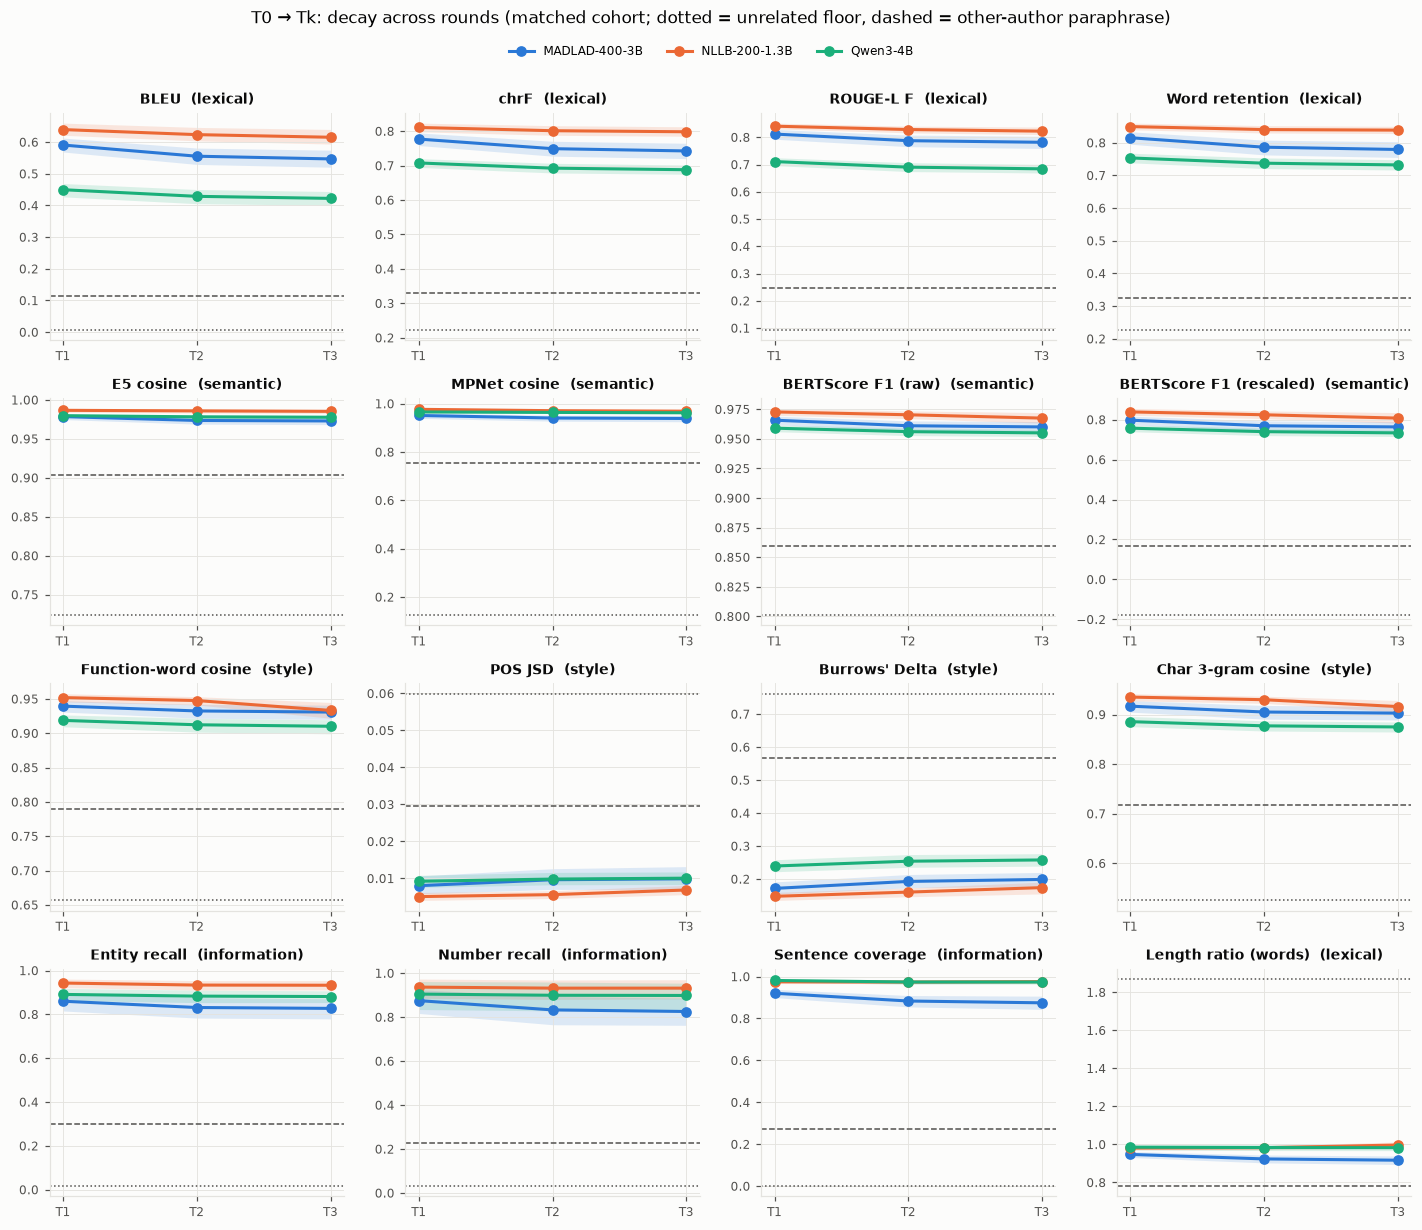

In [6]:
PANELS = [("bleu", "lexical"), ("chrf", "lexical"), ("rougeL", "lexical"), ("word_retention", "lexical"),
          ("e5_cosine", "semantic"), ("mpnet_cosine", "semantic"), ("bertscore_f1", "semantic"),
          ("bertscore_f1_rescaled", "semantic"), ("fw_cosine", "style"), ("pos_jsd", "style"),
          ("burrows_delta", "style"), ("char3_cosine", "style"), ("entity_recall", "information"),
          ("number_recall", "information"), ("sent_coverage", "information"), ("length_ratio", "lexical")]
PANELS = [p for p in PANELS if p[0] in P.columns]
m = summ[summ.cohort == "matched"]
nc = 4
fig, axes = plt.subplots(int(np.ceil(len(PANELS) / nc)), nc, figsize=(13, 2.7 * np.ceil(len(PANELS) / nc)))
for ax, (met, fam) in zip(axes.flat, PANELS):
    for t in TR:
        s = m[(m.metric == met) & (m.translator == t)].sort_values("hyp_stage")
        x = s.hyp_stage.str[1].astype(int)
        ax.plot(x, s["mean"], marker="o", color=COL[t], label=NAMES[t])
        ax.fill_between(x, s.ci_low, s.ci_high, color=COL[t], alpha=0.15, linewidth=0)
    for kind, ls in (("unrelated", ":"), ("cross_source", "--")):
        b = base[(base.metric == met) & (base.kind == kind)]
        if len(b):
            ax.axhline(b["mean"].iloc[0], color=plots.INK2, ls=ls, lw=1)
    ax.set_title(f"{analysis.METRICS[met][0]}  ({fam})", fontsize=9)
    ax.set_xticks([1, 2, 3], ["T1", "T2", "T3"])
for ax in axes.flat[len(PANELS):]:
    ax.axis("off")
fig.suptitle("T0 → Tk: decay across rounds (matched cohort; dotted = unrelated floor, dashed = other-author paraphrase)",
             y=1.03, fontsize=11)
fig.tight_layout()
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=len(TR), bbox_to_anchor=(0.5, 1.01), fontsize=8)
plots.save(fig, "rq1_decay_curves")
plt.show()

## 4. Consecutive-round change (Tk-1 → Tk)

translator             MADLAD-400-3B                                                     NLLB-200-1.3B                                                          Qwen3-4B                        \
step                           T0→T1                 T1→T2                 T2→T3                 T0→T1                 T1→T2                 T2→T3                 T0→T1                 T1→T2   
metric                                                                                                                                                                                           
chrf            0.777 [0.758, 0.795]  0.943 [0.932, 0.954]  0.983 [0.977, 0.988]  0.811 [0.798, 0.824]  0.972 [0.967, 0.977]  0.992 [0.989, 0.994]  0.708 [0.695, 0.720]  0.927 [0.920, 0.934]   
bleu            0.591 [0.569, 0.613]  0.902 [0.885, 0.917]  0.969 [0.959, 0.978]  0.639 [0.621, 0.660]  0.943 [0.932, 0.954]  0.976 [0.967, 0.985]  0.450 [0.427, 0.469]  0.863 [0.849, 0.875]   
word_edit_rate  0.305 [0.280, 0.332]  0.080 [0.065, 0.097]  0.024 [0.017, 0.032]  0.251 [0.234, 0.266]  0.041 [0.032, 0.050]  0.023 [0.013, 0.033]  0.438 [0.420, 0.457]  0.102 [0.091, 0.115]   
bertscore_f1    0.966 [0.962, 0.969]  0.989 [0.987, 0.991]  0.997 [0.996, 0.998]  0.973 [0.970, 0.976]  0.994 [0.992, 0.995]  0.996 [0.994, 0.998]  0.959 [0.956, 0.962]  0.990 [0.989, 0.991]   
mpnet_cosine    0.951 [0.939, 0.961]  0.983 [0.976, 0.989]  0.997 [0.994, 0.998]  0.977 [0.973, 0.980]  0.992 [0.988, 0.996]  0.996 [0.994, 0.998]  0.966 [0.961, 0.970]  0.993 [0.991, 0.995]   
burrows_delta   0.172 [0.154, 0.191]  0.048 [0.038, 0.059]  0.016 [0.010, 0.023]  0.148 [0.135, 0.160]  0.030 [0.023, 0.036]  0.022 [0.012, 0.032]  0.239 [0.222, 0.258]  0.059 [0.052, 0.067]   
exact_equal     0.000 [0.000, 0.000]  0.130 [0.074, 0.197]  0.503 [0.429, 0.573]  0.000 [0.000, 0.000]  0.187 [0.127, 0.253]  0.528 [0.425, 0.639]  0.000 [0.000, 0.000]  0.010 [0.000, 0.026]   

translator                            
step                           T2→T3  
metric                                
chrf            0.971 [0.967, 0.976]  
bleu            0.947 [0.939, 0.954]  
word_edit_rate  0.038 [0.033, 0.044]  
bertscore_f1    0.996 [0.995, 0.996]  
mpnet_cosine    0.998 [0.997, 0.998]  
burrows_delta   0.023 [0.019, 0.027]  
exact_equal     0.155 [0.107, 0.207]

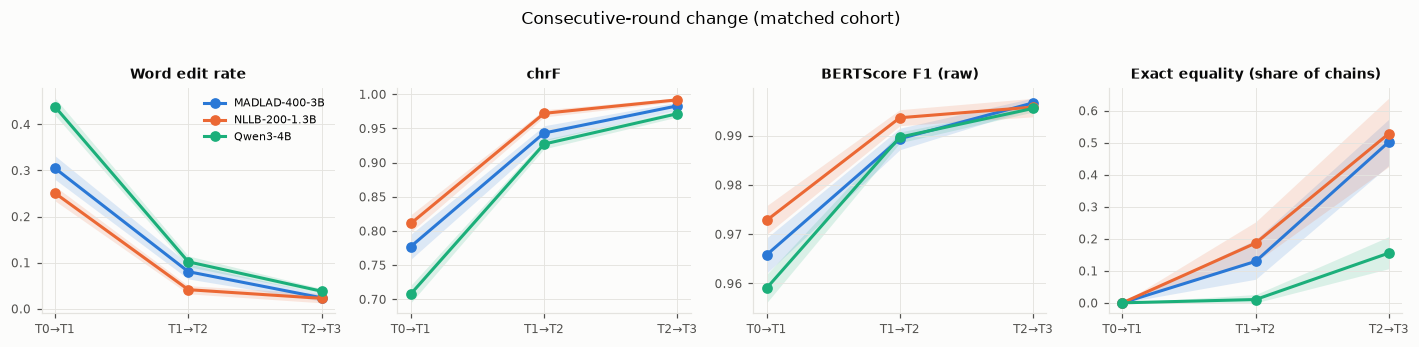

In [7]:
step = TR_PAIRS[(TR_PAIRS.kind == "step") & TR_PAIRS.matched].copy()
step["step"] = step.ref_stage + "→" + step.hyp_stage
STEP_METRICS = ["chrf", "bleu", "word_edit_rate", "bertscore_f1", "mpnet_cosine", "burrows_delta", "exact_equal"]
ssum = pd.concat([analysis.cluster_ci(step, ["translator", "step"], mm, n_boot=NB, seed=SEED) for mm in STEP_METRICS],
                 ignore_index=True)
ssum.to_csv(OUT / "summary_step.csv", index=False)
t = ssum.copy()
t["value"] = t.apply(analysis.fmt_ci, axis=1)
t["translator"] = t.translator.map(NAMES)
display(t.pivot_table(index="metric", columns=["translator", "step"], values="value", aggfunc="first").reindex(STEP_METRICS))

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
order = ["T0→T1", "T1→T2", "T2→T3"]
for ax, met in zip(axes, ["word_edit_rate", "chrf", "bertscore_f1", "exact_equal"]):
    for tt in TR:
        s = ssum[(ssum.metric == met) & (ssum.translator == tt)].set_index("step").reindex(order)
        ax.plot(range(3), s["mean"], marker="o", color=COL[tt], label=NAMES[tt])
        ax.fill_between(range(3), s.ci_low, s.ci_high, color=COL[tt], alpha=0.15, linewidth=0)
    ax.set_xticks(range(3), order)
    ax.set_title(analysis.METRICS[met][0] + (" (share of chains)" if met == "exact_equal" else ""), fontsize=9)
axes[0].legend(fontsize=7)
fig.suptitle("Consecutive-round change (matched cohort)", y=1.03, fontsize=11)
fig.tight_layout()
plots.save(fig, "rq1_consecutive_change")
plt.show()

## 5. Convergence: do chains stabilise?

In [8]:
rows = []
for tt in TR:
    s = step[step.translator == tt]
    c = cum[(cum.translator == tt) & cum.matched]
    r = {"translator": NAMES[tt], "chains": s.item_id.nunique(),
         "T2 == T1 (exact)": s[s.hyp_stage == "T2"].exact_equal.mean(),
         "T3 == T2 (exact)": s[s.hyp_stage == "T3"].exact_equal.mean(),
         "edit rate T0→T1": s[s.hyp_stage == "T1"].word_edit_rate.mean(),
         "edit rate T1→T2": s[s.hyp_stage == "T2"].word_edit_rate.mean(),
         "edit rate T2→T3": s[s.hyp_stage == "T3"].word_edit_rate.mean()}
    for met in ["chrf", "bertscore_f1"]:
        mm = c.groupby("hyp_stage")[met].mean()
        r[f"round-1 share of T3 loss ({met})"] = (1 - mm["T1"]) / (1 - mm["T3"])
    floor = base[(base.metric == "bertscore_f1") & (base.kind == "unrelated")]["mean"].iloc[0]
    r["BERTScore T3, normalised to floor"] = (c[c.hyp_stage == "T3"].bertscore_f1.mean() - floor) / (1 - floor)
    rows.append(r)
conv = pd.DataFrame(rows).set_index("translator")
conv.to_csv(OUT / "convergence.csv")
display(conv.round(3))

,chains,T2 == T1 (exact),T3 == T2 (exact),edit rate T0→T1,edit rate T1→T2,edit rate T2→T3,round-1 share of T3 loss (chrf),round-1 share of T3 loss (bertscore_f1),"BERTScore T3, normalised to floor"
translator,,,,,,,,,
MADLAD-400-3B,193,0.130,0.503,0.305,0.080,0.024,0.866,0.857,0.799
NLLB-200-1.3B,193,0.187,0.528,0.251,0.041,0.023,0.938,0.838,0.837
Qwen3-4B,193,0.010,0.155,0.438,0.102,0.038,0.937,0.912,0.774


Reading the convergence table:
- **Fixed points:** "T3 == T2" is the share of chains in which the third round trip reproduced the second round's text
  *exactly*, i.e. a fixed point of the translator.
- **Round-1 share of T3 loss:** the fraction of the total T0→T3 loss that already happened in the first round trip.

## 6. Translator comparison on the same documents (paired, T3)

pair,MADLAD-400-3B − NLLB-200-1.3B,MADLAD-400-3B − Qwen3-4B,NLLB-200-1.3B − Qwen3-4B
metric,,,
chrf,"-0.056 [-0.079, -0.035]","+0.055 [+0.035, +0.074]","+0.110 [+0.098, +0.123]"
bleu,"-0.068 [-0.100, -0.039]","+0.125 [+0.098, +0.153]","+0.193 [+0.169, +0.217]"
bertscore_f1,"-0.007 [-0.014, -0.002]","+0.005 [+0.001, +0.010]","+0.012 [+0.008, +0.016]"
e5_cosine,"-0.012 [-0.018, -0.007]","-0.005 [-0.010, +0.000]","+0.008 [+0.005, +0.010]"
mpnet_cosine,"-0.030 [-0.047, -0.014]","-0.024 [-0.037, -0.012]","+0.006 [-0.001, +0.013]"
burrows_delta,"+0.025 [+0.002, +0.051]","-0.059 [-0.079, -0.040]","-0.084 [-0.101, -0.066]"
pos_jsd,"+0.003 [+0.000, +0.006]","-0.000 [-0.002, +0.002]","-0.003 [-0.005, -0.002]"
entity_recall,"-0.106 [-0.160, -0.060]","-0.054 [-0.099, -0.012]","+0.052 [+0.028, +0.077]"
number_recall,"-0.106 [-0.164, -0.055]","-0.073 [-0.143, -0.010]","+0.033 [-0.004, +0.078]"


items per comparison: [193 189 163]  articles: [31]


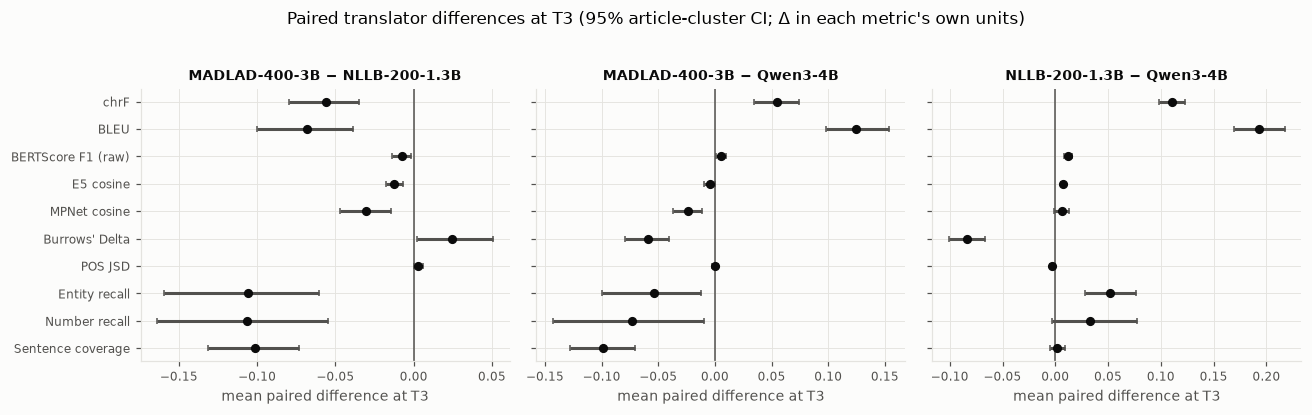

In [9]:
CMP = ["chrf", "bleu", "bertscore_f1", "e5_cosine", "mpnet_cosine", "burrows_delta", "pos_jsd", "entity_recall",
       "number_recall", "sent_coverage"]
CMP = [c for c in CMP if c in P.columns]
pdiff = pd.concat([analysis.paired_differences(TR_PAIRS, mm, TR, stage=s, n_boot=NB, seed=SEED)
                   for mm in CMP for s in ("T1", "T3")], ignore_index=True)
pdiff.to_csv(OUT / "paired_differences.csv", index=False)
x = pdiff[pdiff.stage == "T3"].copy()
x["pair"] = x.a.map(NAMES) + " − " + x.b.map(NAMES)
x["diff [95% CI]"] = x.apply(lambda r: f"{r.mean_diff:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]", axis=1)
display(x.pivot_table(index="metric", columns="pair", values="diff [95% CI]", aggfunc="first").reindex(CMP))
print("items per comparison:", x.n_items.unique(), " articles:", x.n_articles.unique())

fig, axes = plt.subplots(1, len(x.pair.unique()), figsize=(4 * len(x.pair.unique()), 3.6), sharey=True)
axes = np.atleast_1d(axes)
for ax, (pr, g) in zip(axes, x.groupby("pair", sort=False)):
    g = g.set_index("metric").reindex(CMP[::-1])
    ax.errorbar(g.mean_diff, range(len(g)), xerr=[g.mean_diff - g.ci_low, g.ci_high - g.mean_diff], fmt="o",
                color=plots.INK, ecolor=plots.INK2, capsize=2, markersize=5)
    ax.axvline(0, color=plots.INK2, lw=1)
    ax.set_yticks(range(len(g)), [analysis.METRICS[mm][0] for mm in g.index])
    ax.set_title(pr, fontsize=9)
    ax.set_xlabel("mean paired difference at T3")
fig.suptitle("Paired translator differences at T3 (95% article-cluster CI; Δ in each metric's own units)", y=1.03,
             fontsize=11)
fig.tight_layout()
plots.save(fig, "rq1_paired_differences_T3")
plt.show()

## 7. Information preservation: entities, numbers, sentences

These are **heuristic warnings, not validated factual errors**:
- **Entity loss:** a named entity of the original is no longer found verbatim in the output. Paraphrases and
  spelling variants also trigger it.
- **Number change:** the multiset of numbers differs. Unit conversions and reformatting (e.g. "11.2 billion" →
  "11,200 million") also count.
- **Sentence omission:** an original sentence has no output sentence above the MPNet cosine threshold.

None of these has been manually validated. The unrelated-pair row shows how often each flag fires when two texts
share no content.

,flag_entity_loss,flag_number_change,flag_sentence_omission,flag_any_content_warning
"(MADLAD-400-3B, T1)",0.570,0.311,0.435,0.736
"(MADLAD-400-3B, T2)",0.617,0.352,0.528,0.777
"(MADLAD-400-3B, T3)",0.627,0.352,0.549,0.782
"(NLLB-200-1.3B, T1)",0.368,0.155,0.233,0.487
"(NLLB-200-1.3B, T2)",0.404,0.187,0.249,0.554
"(NLLB-200-1.3B, T3)",0.404,0.187,0.238,0.549
"(Qwen3-4B, T1)",0.523,0.238,0.171,0.658
"(Qwen3-4B, T2)",0.544,0.249,0.207,0.694
"(Qwen3-4B, T3)",0.560,0.249,0.212,0.694
"(baseline, cross_source)",1.000,0.964,1.000,1.000


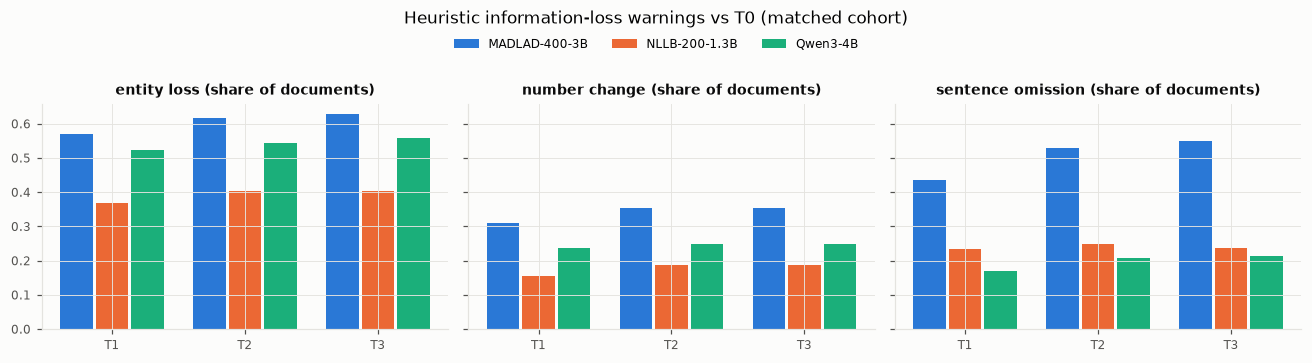

In [10]:
FLAGS = [c for c in ["flag_entity_loss", "flag_number_change", "flag_sentence_omission", "flag_any_content_warning"]
         if c in P.columns]
fr = cum[cum.matched].groupby(["translator", "hyp_stage"])[FLAGS].mean()
fr = pd.concat([fr, BASE.groupby(["translator", "kind"])[FLAGS].mean().rename_axis(["translator", "hyp_stage"])])
fr.to_csv(OUT / "information_flags.csv")
disp = fr.copy()
disp.index = [(NAMES.get(a, a), b) for a, b in disp.index]
display(disp.round(3))

fig, axes = plt.subplots(1, len(FLAGS) - 1, figsize=(12, 3), sharey=True)
w = 0.8 / len(TR)
for ax, f in zip(axes, FLAGS[:-1]):
    for i, tt in enumerate(TR):
        v = fr.loc[tt][f].reindex(["T1", "T2", "T3"])
        ax.bar(np.arange(3) + (i - (len(TR) - 1) / 2) * w, v, width=w * 0.92, color=COL[tt], label=NAMES[tt])
    ax.set_xticks(range(3), ["T1", "T2", "T3"])
    ax.set_title(f.replace("flag_", "").replace("_", " ") + " (share of documents)", fontsize=9)
fig.suptitle("Heuristic information-loss warnings vs T0 (matched cohort)", y=1.08, fontsize=11)
fig.tight_layout()
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=len(TR), bbox_to_anchor=(0.5, 1.03), fontsize=8)
plots.save(fig, "rq1_information_flags")
plt.show()

In [11]:
full = pd.read_parquet(paths.local("pair_metrics_full.parquet"))
lost = full[(full.kind == "cumulative") & (full.hyp_stage == "T3") & full.matched & full.translator.isin(TR)]
top = (lost.assign(e=lost.lost_entities_json.map(json.loads)).explode("e").dropna(subset=["e"])
       .groupby("translator").e.value_counts().groupby(level=0).head(8).rename("documents").reset_index())
top["translator"] = top.translator.map(NAMES)
print("Most frequently 'lost' entity strings at T3 (inspect: many are spelling/translation variants, not losses)")
display(top.pivot_table(index=top.groupby("translator").cumcount(), columns="translator",
                        values=["e", "documents"], aggfunc="first").swaplevel(axis=1).sort_index(axis=1))
by_src = analysis.cluster_ci(cum[cum.matched & (cum.hyp_stage == "T3")], ["translator", "source_label"],
                             "bertscore_f1", n_boot=NB, seed=SEED)
by_src.to_csv(OUT / "bertscore_T3_by_source.csv", index=False)
display(by_src.pivot_table(index="source_label", columns="translator", values="mean").rename(columns=NAMES)
        .rename_axis(index="BERTScore F1, T0→T3, by original source"))

Most frequently 'lost' entity strings at T3 (inspect: many are spelling/translation variants, not losses)


translator MADLAD-400-3B                          NLLB-200-1.3B                   Qwen3-4B                   
               documents                        e     documents                e documents                  e
0                     11                       us            10               us        17                 us
1                      6               healthcare             6  bashar al-assad        10            britain
2                      6                medicines             6             shia        10                 uk
3                      5  care quality commission             4               uk         5       ciaran clark
4                      5             ciaran clark             3           bosnia         4             tories
5                      5                     shia             3          britain         3                 ai
6                      5            teluk wondama             2        australia         3            england
7                      5                       uk             2          british         3  liberal democrats

translator,MADLAD-400-3B,NLLB-200-1.3B,Qwen3-4B
"BERTScore F1, T0→T3, by original source",,,
BigScience,0.953,0.966,0.948
Eleuther-AI,0.945,0.964,0.946
Human,0.960,0.958,0.950
LLAMA,0.960,0.965,0.956
OpenAI,0.970,0.980,0.967
PaLM,0.970,0.972,0.963
Tsinghua,0.962,0.968,0.956


## 8. Segmentation and length: the translators' design differs

In [12]:
seg = cum[cum.matched].groupby(["translator", "hyp_stage"])[["length_ratio", "sentence_count_ratio",
                                                              "sent_len_ratio"]].mean()
seg.index = [(NAMES[a], b) for a, b in seg.index]
display(seg.round(3))
tt = D["translators_table"].set_index("translator")
print("Unit of translation (from configs/translators.yaml):")
for t in TR:
    print(f"  {NAMES[t]:<16} {tt.loc[t, 'model_checkpoint']}")

,length_ratio,sentence_count_ratio,sent_len_ratio
"(MADLAD-400-3B, T1)",0.948,0.914,1.086
"(MADLAD-400-3B, T2)",0.924,0.867,1.149
"(MADLAD-400-3B, T3)",0.917,0.852,1.168
"(NLLB-200-1.3B, T1)",0.981,1.011,0.974
"(NLLB-200-1.3B, T2)",0.983,1.051,0.948
"(NLLB-200-1.3B, T3)",0.997,1.138,0.921
"(Qwen3-4B, T1)",0.986,1.007,0.983
"(Qwen3-4B, T2)",0.984,1.007,0.983
"(Qwen3-4B, T3)",0.983,1.007,0.981


Unit of translation (from configs/translators.yaml):
  MADLAD-400-3B    ['google/madlad400-3b-mt']
  NLLB-200-1.3B    ['facebook/nllb-200-distilled-1.3B']
  Qwen3-4B         ['Qwen/Qwen3-4B-Instruct-2507']


**Segmentation is a design confound.**
- **MADLAD and NLLB** translate sentence-sized segments. MADLAD packs sentences up to 300 tokens; NLLB translates one
  sentence per segment. Sentence boundaries are therefore preserved almost by construction.
- **Qwen (and any LLM translator)** translates the whole document in one prompt and can merge or split sentences.

Sentence-count and punctuation metrics reflect this design choice as well as each model's behaviour.

## 9. Representative examples

In [13]:
txt = T.set_index("text_id").text
f0 = D["features"][(D["features"].stage == "T0") & D["features"].item_id.isin(D["matched_items"])]
ex_item = f0.assign(d=(f0.n_words - 70).abs()).sort_values(["d", "item_id"]).item_id.iloc[0]
print("Typical short document:", ex_item)
print(f"\nT0: {analysis.excerpt(txt[ex_item + '|original|T0'], 70)}")
for t in TR:
    for k in (1, 3):
        print(f"\n{NAMES[t]} T{k}: {analysis.excerpt(txt[f'{ex_item}|{t}|T{k}'], 70)}")

Typical short document: xsum|LLAMA|xsum-4720

T0: The 35-year-old former West Ham and Derby man was approaching the end of his contract at the club. Bywater, whose previous clubs include Millwall and [...]

MADLAD-400-3B T1: The 35-year-old former West Ham and Derby player was approaching the end of his contract with the club. Bywater, whose previous clubs include Millwall and [...]

MADLAD-400-3B T3: The 35-year-old former West Ham and Derby player was approaching the end of his contract with the club. Bywater, whose previous clubs include Millwall and [...]

NLLB-200-1.3B T1: The 35-year-old former West Ham and Derby player was nearing the end of his contract with the club. Bywater, whose previous clubs include Millwall and [...]

NLLB-200-1.3B T3: The 35-year-old former West Ham and Derby player was nearing the end of his contract with the club. Bywater, whose previous clubs include Millwall and [...]

Qwen3-4B T1: The 35-year-old former West Ham and Derby player was approaching the

In [14]:
cols = ["bertscore_f1", "chrf", "entity_recall", "number_recall"]
ex_rows = []
for t in TR:
    c = cum[(cum.translator == t) & cum.matched & (cum.hyp_stage == "T3")].sort_values("bertscore_f1")
    worst = c.iloc[0]
    ex_rows.append({"translator": t, "kind": "largest semantic drop", "item_id": worst.item_id, **worst[cols].to_dict()})
    print(f"\n=== {NAMES[t]}: largest BERTScore drop at T3 ({worst.item_id}, {worst.ref_words} words) ===")
    print(worst[cols].round(3).to_dict())
    print("T0:", analysis.excerpt(txt[worst.ref_text_id], 45))
    print("T3:", analysis.excerpt(txt[worst.hyp_text_id], 45))
pd.DataFrame(ex_rows).to_csv(OUT / "examples.csv", index=False)


=== MADLAD-400-3B: largest BERTScore drop at T3 (xsum|BigScience|xsum-4716, 80.0 words) ===
{'bertscore_f1': 0.8808183539293304, 'chrf': 0.4521183412934562, 'entity_recall': 0.4285714285714286, 'number_recall': 0.5714285714285714}
T0: Greg Dyke has invited Astle's widow Laraine and his daughters, Claire and Dawn, to Wembley Stadium on 10 August. The ex-West Bromwich Albion and England [...]
T3: On 13 October 2007, it was announced that the Chicago Fire had signed former West Bromwich Albion player Chris McGugan as their new coach.[1] McGugan [...]

=== NLLB-200-1.3B: largest BERTScore drop at T3 (xsum|Human|xsum-4712, 382.0 words) ===
{'bertscore_f1': 0.9028486450942218, 'chrf': 0.6511539286413749, 'entity_recall': 1.0, 'number_recall': 0.75}
T0: Huw Irranca-Davies, who has announced he is leaving the shadow frontbench, told Radio Wales his party needed to "consistently re-invigorate" itself. He said the party [...]
T3: Huw Irranca-Davies, who has announced he is leaving the shadow be

## 10. Key results

In [15]:
m3 = summ[(summ.cohort == "matched") & (summ.hyp_stage == "T3")].set_index(["metric", "translator"])
m1 = summ[(summ.cohort == "matched") & (summ.hyp_stage == "T1")].set_index(["metric", "translator"])
lines = []
for t in TR:
    lines.append(f"- **{NAMES[t]}**: chrF {m1.loc[('chrf', t), 'mean']:.3f} (T1) → {m3.loc[('chrf', t), 'mean']:.3f} (T3); "
                 f"BERTScore F1 {m1.loc[('bertscore_f1', t), 'mean']:.3f} → {m3.loc[('bertscore_f1', t), 'mean']:.3f}; "
                 f"entity recall {m3.loc[('entity_recall', t), 'mean']:.3f} at T3; "
                 f"T3 identical to T2 in {conv.loc[NAMES[t], 'T3 == T2 (exact)']:.0%} of chains.")
display(Markdown("\n".join(lines) + f"\n\n(n = {len(D['matched_items'])} matched documents per translator and stage, "
                 f"{D['cohort'][D['cohort'].matched].article_id.nunique()} articles)"))

- **MADLAD-400-3B**: chrF 0.777 (T1) → 0.743 (T3); BERTScore F1 0.966 → 0.960; entity recall 0.827 at T3; T3 identical to T2 in 50% of chains.
- **NLLB-200-1.3B**: chrF 0.811 (T1) → 0.798 (T3); BERTScore F1 0.973 → 0.968; entity recall 0.933 at T3; T3 identical to T2 in 53% of chains.
- **Qwen3-4B**: chrF 0.708 (T1) → 0.688 (T3); BERTScore F1 0.959 → 0.955; entity recall 0.881 at T3; T3 identical to T2 in 16% of chains.

(n = 193 matched documents per translator and stage, 31 articles)

## Interpretation

Values are from the matched cohort (193 documents, 31 articles) and the tables above. If translators are added or
the data change, re-read the tables; this text describes the run committed with this notebook.

**1. Almost all decay happens in the first round trip.**
- Across translators, 84-94% of the total T0→T3 loss (chrF, BERTScore) is already present at T1.
- Consecutive-round change then collapses. Word edit rate falls from 0.25-0.44 (T0→T1) to 0.02-0.04 (T2→T3).
- By T3, about half of the MADLAD (50%) and NLLB (53%) chains are **exact fixed points**: the third round trip
  reproduces the second word for word. Qwen keeps rephrasing slightly (15% fixed points).
- The "ship" is mostly rebuilt once and then stays put. Repeated MT converges quickly towards a translator-specific
  attractor text rather than drifting steadily.

**2. Lexical and semantic decay tell different stories.**
- **Lexical overlap:** Qwen rewrites the most wording (BLEU 0.45 vs 0.59 MADLAD and 0.64 NLLB at T1; chrF
  0.71 / 0.78 / 0.81).
- **Meaning:** all three stay far closer to the original than an independent same-content text written by another
  author.
  - MPNet cosine 0.94-0.97 at T3, vs 0.75 for the other-author paraphrase.
  - BERTScore F1 0.955-0.968, vs 0.86.
- **Qwen's lower lexical scores reflect paraphrase, not lost content.** Its sentence coverage (0.97) and MPNet
  similarity are at or above MADLAD's, and it preserves more entities than MADLAD (0.88 vs 0.83 at T3).
- **NLLB is the most conservative on every family:** the highest lexical and semantic similarity and the best entity
  recall (0.93).

**3. Style drifts more for the LLM translator.**
- Burrows' Delta at T3 is 0.26 for Qwen vs 0.17-0.20 for the MT systems.
- Qwen's function-word and character-trigram profiles move furthest from the original.
- POS distributions barely change for any translator: Jensen-Shannon divergence ≤ 0.01, vs 0.03 for the other-author
  paraphrase.
- The surface style changes while the grammar stays the same.

**4. Information-loss warnings are frequent but mostly benign, and MADLAD is the outlier.**
- **MADLAD** has the lowest sentence coverage (0.875 at T3) and the highest rates of entity-, number- and
  sentence-omission warnings.
  - Its sentence count shrinks by about 15% by T3, because it merges sentences.
  - The largest MADLAD drop is a genuine failure: one round trip replaced the article with an unrelated,
    Wikipedia-style text ("Chicago Fire ... [1]").
- **NLLB** splits sentences increasingly (sentence count +14% by T3). In its worst case, an unrelated sentence about
  the European Parliament was inserted.
- **Inspecting the most frequently "lost" entities** shows that many are normalisations ("US", "UK", "Britain"
  rendered differently) rather than losses, so these rates are upper bounds on real information loss.

**5. Translators differ significantly, and the ranking depends on the metric family.**
- Paired T3 differences on identical documents (article-cluster CIs) rank:
  - lexical similarity: NLLB > MADLAD > Qwen;
  - stylistic drift: Qwen > MADLAD > NLLB;
  - entity, number and sentence preservation: MADLAD lowest.
- The NLLB-Qwen gaps in BERTScore and E5 are small (about 0.01) but excluded from zero.

## Limitations
- **Sample size:** 31 original articles carry 200 documents, and every interval is clustered on articles. The rarer
  failure modes rest on few cases.
- **Matched cohort:** it excludes the 7 documents with an invalid stage in some translator. Repetition and
  token-cap failures are not random, so the matched cohort slightly favours "easy" documents. The all-available
  summaries are in `results/rq1/summary_cumulative.csv`.
- **Segmentation confound:** MADLAD and NLLB translate sentence segments and Qwen translates whole documents.
  Sentence-count and sentence-coverage metrics partly measure this design difference.
- **Heuristic information flags:** the entity, number and sentence flags are heuristics (string presence,
  number-multiset equality, an MPNet cosine threshold of 0.6). No flag was manually validated as a factual error.
- **Metric conventions:**
  - BERTScore uses roberta-large layer 17, windowed for texts over 510 tokens (281 texts), and is reported raw and
    baseline-rescaled.
  - E5 and MPNet embed long texts as token-weighted means of sentence-packed chunks. Nothing was truncated.
- **Missing baseline:** the English-paraphrasing baseline of the original project is not part of this corpus, so RQ1
  here compares translators with each other and with the in-corpus reference pairs.
- **Single direction and settings:** only English↔Spanish, one decoding setting per translator (greedy), and one
  dataset (XSum).